# Apriori – Unsupervised Learning (selbst implementiert)

**Ziel:** Aus Warenkörben häufig gemeinsam gekaufte Produkte finden und daraus Assoziationsregeln ableiten. Wir nutzen nur die Python-Standardbibliothek (`itertools`), **keine fertige Apriori-Funktion**.

**Ablauf:** Warenkörbe → Support → häufige Einzelprodukte → Kandidaten erzeugen → Apriori-Pruning → Supportprüfung → Regeln.

> Unsupervised Learning: Es gibt keine vorgegebenen Zielklassen. Wir entdecken Muster in den Einkäufen.

**Voraussetzungen:** Für den Apriori-Algorithmus genügt die Python-Standardbibliothek. Die Grafiken werden mit `matplotlib` in der separaten Datei `apriori_plot.py` erstellt. **Beide Dateien müssen im selben Ordner liegen.**

## 1. Beispieldaten

Wir betrachten **20 fiktive Einkäufe** mit sechs verschiedenen Produkten. Die Daten sind bewusst so gewählt, dass sowohl häufige Kombinationen als auch das **Apriori-Pruning** sichtbar werden.

Ein **Mindest-Support von 30 %** bedeutet: Eine Kombination muss in mindestens **6 von 20 Einkäufen** vorkommen.

In [1]:
warenkoerbe = [
    {"Brot", "Milch", "Butter"},
    {"Brot", "Milch", "Butter"},
    {"Brot", "Milch", "Butter"},
    {"Brot", "Milch", "Butter"},
    {"Brot", "Milch", "Butter"},
    {"Brot", "Milch", "Butter"},
    {"Brot", "Milch", "Kaffee"},
    {"Brot", "Milch", "Kaffee"},
    {"Brot", "Milch", "Kaffee"},
    {"Brot", "Milch"},
    {"Brot", "Butter", "Kaffee"},
    {"Brot", "Butter", "Kaffee"},
    {"Brot", "Butter", "Kaffee"},
    {"Milch", "Butter"},
    {"Milch", "Butter"},
    {"Kaffee", "Zucker"},
    {"Kaffee", "Zucker"},
    {"Kaffee", "Zucker"},
    {"Kaffee", "Zucker", "Tee"},
    {"Kaffee", "Zucker", "Tee"},
]
min_support = 0.30

for nummer, korb in enumerate(warenkoerbe, start=1):
    print(f"{nummer:2}: {', '.join(sorted(korb))}")
print(f"\nEinkäufe: {len(warenkoerbe)}, Mindest-Support: {min_support:.0%}")

 1: Brot, Butter, Milch
 2: Brot, Butter, Milch
 3: Brot, Butter, Milch
 4: Brot, Butter, Milch
 5: Brot, Butter, Milch
 6: Brot, Butter, Milch
 7: Brot, Kaffee, Milch
 8: Brot, Kaffee, Milch
 9: Brot, Kaffee, Milch
10: Brot, Milch
11: Brot, Butter, Kaffee
12: Brot, Butter, Kaffee
13: Brot, Butter, Kaffee
14: Butter, Milch
15: Butter, Milch
16: Kaffee, Zucker
17: Kaffee, Zucker
18: Kaffee, Zucker
19: Kaffee, Tee, Zucker
20: Kaffee, Tee, Zucker

Einkäufe: 20, Mindest-Support: 30%


## 2. Support: Wie häufig ist eine Kombination?

$$\operatorname{Support}(X)=\frac{\text{Einkäufe, die alle Produkte aus }X\text{ enthalten}}{\text{Alle Einkäufe}}$$

`issubset()` prüft, ob **alle** Produkte der gesuchten Kombination im Warenkorb liegen. Die Funktion berechnet den Support für jede beliebige Kombination.

In [2]:
def support(produkte):
    anzahl = sum(produkte.issubset(korb) for korb in warenkoerbe)
    return anzahl / len(warenkoerbe)

beispiel = frozenset({"Brot", "Milch"})
anzahl = sum(beispiel.issubset(korb) for korb in warenkoerbe)
print(f"Brot + Milch: {anzahl} von {len(warenkoerbe)} Einkäufen = {support(beispiel):.0%}")

Brot + Milch: 10 von 20 Einkäufen = 50%


## 3. Erste Iteration: Einzelprodukte prüfen

Zunächst finden wir alle verschiedenen Produkte. Jedes Produkt bildet einen Kandidaten der Größe 1. Wir behalten nur Produkte, die den Mindest-Support erreichen.

In [3]:
produkte = sorted(set().union(*warenkoerbe))
haeufige_kombinationen = []
protokoll = []

for produkt in produkte:
    kandidat = frozenset({produkt})
    wert = support(kandidat)
    behalten = wert >= min_support
    print(f"{produkt:8} | Support: {wert:5.0%} | {'BEHALTEN' if behalten else 'VERWERFEN'}")
    protokoll.append((1, kandidat, "behalten" if behalten else "support", wert))
    if behalten:
        haeufige_kombinationen.append(kandidat)

Brot     | Support:   65% | BEHALTEN
Butter   | Support:   55% | BEHALTEN
Kaffee   | Support:   55% | BEHALTEN
Milch    | Support:   60% | BEHALTEN
Tee      | Support:   10% | VERWERFEN
Zucker   | Support:   25% | VERWERFEN


## 4. Apriori: Größere Kombinationen finden

**Apriori-Prinzip:** Wenn eine Teilkombination nicht häufig ist, kann auch keine größere Kombination, die diese Teilkombination enthält, häufig sein.

Beispiel: Wenn `Brot + Kaffee` unter dem Mindest-Support liegt, muss `Brot + Kaffee + Milch` **nicht** mehr gezählt werden.

In jeder Iteration:

1. Kandidaten mit einem zusätzlichen Produkt erzeugen.
2. **Pruning:** Kandidaten überspringen, wenn eine direkte Teilkombination nicht häufig war.
3. Für die übrigen Kandidaten Support berechnen und zu seltene verwerfen.

Die Ausgaben zeigen ausdrücklich den Unterschied zwischen **PRUNING** (kein Support nötig) und **SUPPORT ZU KLEIN** (Support wurde berechnet).

In [4]:
from itertools import combinations

def anzeigen(kombination):
    return " + ".join(sorted(kombination))

# Bereits gefundene häufige Einzelprodukte übernehmen.
ergebnis = haeufige_kombinationen.copy()
groesse = 2

while haeufige_kombinationen:
    print(f"\n--- Iteration: {groesse} Produkte pro Kombination ---")

    # Kandidaten aus allen Produkten der vorherigen häufigen Mengen bilden.
    relevante_produkte = sorted(set().union(*haeufige_kombinationen))
    kandidaten = [
        frozenset(k) for k in combinations(relevante_produkte, groesse)
    ]
    neue_kombinationen = []
    vorherige = set(haeufige_kombinationen)

    for kandidat in kandidaten:
        # Nur dann Support berechnen, wenn ALLE direkten Teilmengen häufig sind.
        teilkombinationen = (
            frozenset(teil) for teil in combinations(sorted(kandidat), groesse - 1)
        )
        if not all(teil in vorherige for teil in teilkombinationen):
            protokoll.append((groesse, kandidat, "pruning", None))
            print(f"{anzeigen(kandidat):30} | PRUNING (Teilkombination zu selten)")
            continue

        wert = support(kandidat)
        if wert >= min_support:
            protokoll.append((groesse, kandidat, "behalten", wert))
            neue_kombinationen.append(kandidat)
            print(f"{anzeigen(kandidat):30} | {wert:5.0%} | BEHALTEN")
        else:
            protokoll.append((groesse, kandidat, "support", wert))
            print(f"{anzeigen(kandidat):30} | {wert:5.0%} | SUPPORT ZU KLEIN")

    print(f"=> {len(neue_kombinationen)} häufige Kombination(en) der Größe {groesse}")
    ergebnis.extend(neue_kombinationen)
    haeufige_kombinationen = neue_kombinationen
    groesse += 1


--- Iteration: 2 Produkte pro Kombination ---
Brot + Butter                  |   45% | BEHALTEN
Brot + Kaffee                  |   30% | BEHALTEN
Brot + Milch                   |   50% | BEHALTEN
Butter + Kaffee                |   15% | SUPPORT ZU KLEIN
Butter + Milch                 |   40% | BEHALTEN
Kaffee + Milch                 |   15% | SUPPORT ZU KLEIN
=> 4 häufige Kombination(en) der Größe 2

--- Iteration: 3 Produkte pro Kombination ---
Brot + Butter + Kaffee         | PRUNING (Teilkombination zu selten)
Brot + Butter + Milch          |   30% | BEHALTEN
Brot + Kaffee + Milch          | PRUNING (Teilkombination zu selten)
Butter + Kaffee + Milch        | PRUNING (Teilkombination zu selten)
=> 1 häufige Kombination(en) der Größe 3

--- Iteration: 4 Produkte pro Kombination ---
=> 0 häufige Kombination(en) der Größe 4


### Was zeigt die Ausgabe?

- **BEHALTEN:** Die Kombination erreicht den Mindest-Support.
- **SUPPORT ZU KLEIN:** Die Kombination wurde gezählt, kommt aber zu selten vor.
- **PRUNING:** Mindestens eine kleinere Teilkombination war bereits zu selten. Die größere Kombination wird deshalb **ohne Supportberechnung** verworfen.

Das Pruning spart bei großen Datensätzen viele unnötige Prüfungen. In dieser einfachen Variante werden zunächst alle Kandidaten aus relevanten Produkten gebildet; eine optimierte Apriori-Implementierung würde bereits die Kandidatenerzeugung stärker einschränken.

## 5. Alle häufigen Kombinationen

Nur Kombinationen mit mindestens 30 % Support bleiben übrig.

In [5]:
for kombination in sorted(ergebnis, key=lambda k: (len(k), sorted(k))):
    print(f"{anzeigen(kombination):30} | Support: {support(kombination):5.0%}")

Brot                           | Support:   65%
Butter                         | Support:   55%
Kaffee                         | Support:   55%
Milch                          | Support:   60%
Brot + Butter                  | Support:   45%
Brot + Kaffee                  | Support:   30%
Brot + Milch                   | Support:   50%
Butter + Milch                 | Support:   40%
Brot + Butter + Milch          | Support:   30%


## 6. Visualisierung: Welche Kombinationen sind häufig?

Das Balkendiagramm zeigt den **Support aller tatsächlich geprüften Kombinationen**. Die gestrichelte Linie markiert den Mindest-Support von 30 %. Grün bedeutet *behalten*, Rot bedeutet *Support zu klein*. Kandidaten, die durch das Apriori-Prinzip bereits vorher ausgeschlossen wurden, erscheinen hier nicht: Ihr Support musste gar nicht berechnet werden.

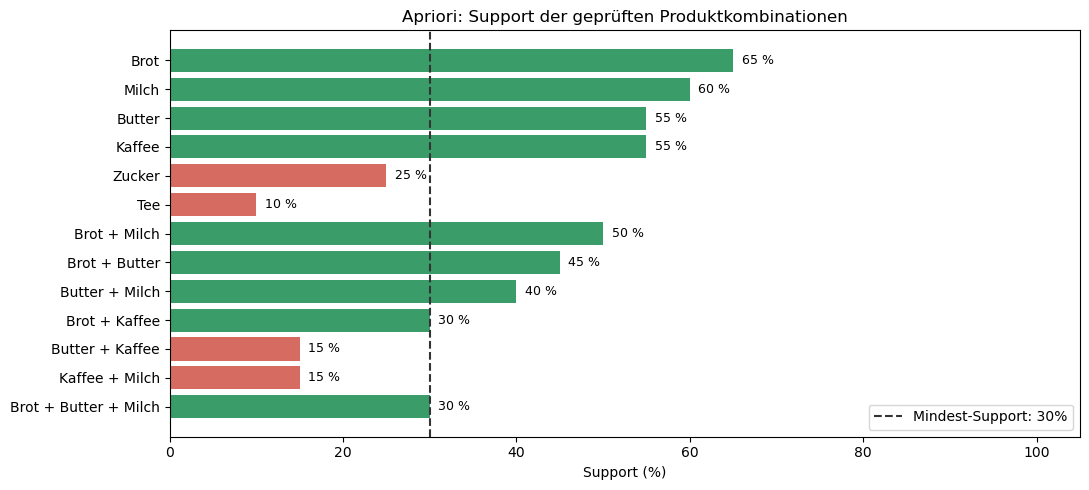

In [6]:
from apriori_plot import plot_support

plot_support(protokoll, min_support, file_name="apriori_kombination.png")

## 7. Assoziationsregeln: Support vs. Confidence

**Support** fragt: *Wie oft werden Brot und Milch gemeinsam gekauft (bezogen auf alle Einkäufe)?*

**Confidence** fragt: *Wie häufig enthält ein Einkauf auch Milch, wenn bereits Brot darin liegt?*

$$\operatorname{Confidence}(A\rightarrow B)=\frac{\operatorname{Support}(A\cup B)}{\operatorname{Support}(A)}$$

Wir betrachten nur Regeln aus häufigen Kombinationen und behalten Regeln mit mindestens **70 % Confidence**. Eine Assoziation beweist keine Ursache-Wirkung-Beziehung.

In [7]:
min_confidence = 0.70
regeln = []

for kombination in ergebnis:
    if len(kombination) < 2:
        continue

    for links_groesse in range(1, len(kombination)):
        for links_tuple in combinations(sorted(kombination), links_groesse):
            links = frozenset(links_tuple)
            rechts = kombination - links
            confidence = support(kombination) / support(links)

            if confidence >= min_confidence:
                regeln.append((links, rechts, confidence))

for links, rechts, confidence in sorted(
    regeln, key=lambda r: (-r[2], anzeigen(r[0]), anzeigen(r[1]))
):
    print(f"{anzeigen(links):18} -> {anzeigen(rechts):18} | Confidence: {confidence:5.0%}")

Milch              -> Brot               | Confidence:   83%
Butter             -> Brot               | Confidence:   82%
Brot               -> Milch              | Confidence:   77%
Butter + Milch     -> Brot               | Confidence:   75%
Butter             -> Milch              | Confidence:   73%
